In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt




In [3]:
#Load in the dataset
penguin_size = pd.read_csv('/content/penguins_size.csv')

#drop columns with NaN
penguin_size_cleaned = penguin_size.dropna()
penguin_size_cleaned.head()

penguin_size_cleaned.to_csv('cleaned_penguin_size_data.csv', index=False)

**1. Preparing Features and Target Variables**

We will separate features (X) and target variable (y) from the dataset.

Features are chosen by "culmen length" and flipper length", and we will use these features to predict species.

In [4]:
X = penguin_size_cleaned[['culmen_length_mm','flipper_length_mm']]
y = penguin_size_cleaned['species']

**2. Encoding and Splitting the Dataset**


* Since the target variable "Species" is categorical we will be using Label Encoder to convert it to numerical form.
* Then split the data into 70% training and 30% testing sets. The random_state parameter ensures reproducibility of the data.



In [5]:
y = LabelEncoder().fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Total number of data points:", len(X))
print(f"Training data points:", len(X_train))
print(f"Testing testing points:", len(X_test))


Total number of data points: 334
Training data points: 233
Testing testing points: 101


In [7]:
X_train

,culmen_length_mm,flipper_length_mm
292,48.2,221.0
302,47.4,212.0
62,37.6,185.0
181,52.8,205.0
15,36.6,185.0
...,...,...
194,50.9,196.0
77,37.2,184.0
112,39.7,193.0
277,45.5,220.0


In [8]:
X_test

,culmen_length_mm,flipper_length_mm
30,39.5,178.0
317,46.9,222.0
79,42.1,195.0
201,49.8,198.0
63,41.1,192.0
...,...,...
7,39.2,195.0
215,55.8,207.0
99,43.2,192.0
35,39.2,196.0


**3. Creating and Training the Model**

Create a Gaussian Naive Bayes and train it on the training data using the fit method.

In [9]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)

GaussianNB()

**4. Making Predictions**

Use the trained model to make predictions on the testing data

In [10]:
y_pred = gnb.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"The Accuracy of Prediction on Species is: {accuracy}")

The Accuracy of Prediction on Species is: 0.9702970297029703


**5. Visualizing Results**

1. Confusion Matrix: Summarizes prediction results by showing true positives, false positives, true negatives, and false negatives. It helps visualize how well the classifier distinguishes between different classes

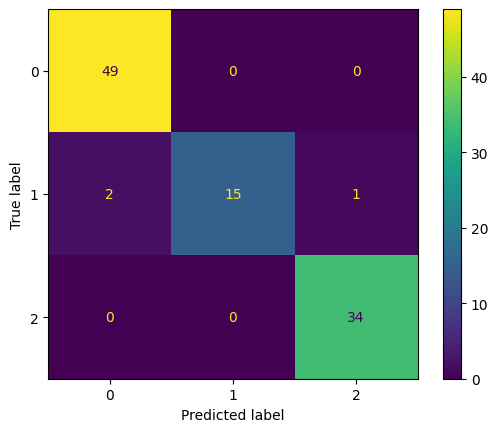

In [11]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)



